In [ ]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats

# Publication-quality settings
mpl.rcParams['font.family'] = 'Times New Roman'
mpl.rcParams['font.size'] = 11
mpl.rcParams['axes.labelsize'] = 12
mpl.rcParams['axes.titlesize'] = 13
mpl.rcParams['xtick.labelsize'] = 10
mpl.rcParams['ytick.labelsize'] = 10
mpl.rcParams['legend.fontsize'] = 10
mpl.rcParams['figure.dpi'] = 100
mpl.rcParams['savefig.dpi'] = 600
mpl.rcParams['savefig.bbox'] = 'tight'

In [ ]:
RESULTS_DIR = os.path.join('..', 'results', 'noise_experiments')
BASELINE_DIR = os.path.join('..', 'results')
FIGURES_DIR = os.path.join('..', 'results', 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

TARGET_PATHOLOGIES = [
    'Pleural Effusion',
    'Consolidation',
    'Cardiomegaly', 
    'Atelectasis', 
    'Edema'
]

df = pd.read_csv(os.path.join(RESULTS_DIR, 'all_results.csv'))
print(f"Loaded {len(df)} noise experiments")
print(f"Noise types: {df['noise_type'].unique()}")
print(f"Noise rates: {sorted(df['noise_rate'].unique())}")
print(f"Seeds: {sorted(df['seed'].unique())}")

baseline_path = os.path.join(BASELINE_DIR, 'baseline_clean_test_results.json')
with open(baseline_path) as f:
    baseline = json.load(f)

BASELINE_MEAN_AUC = baseline['test_mean_auc']
BASELINE_PER_PATH = baseline['test_per_pathology_auc']

print(f"\nBaseline mean AUC: {BASELINE_MEAN_AUC:.4f}")
print(f"Baseline per-pathology:")
for k, v in BASELINE_PER_PATH.items():
    print(f"  {k:20s}: {v:.4f}")

Loaded 24 noise experiments
Noise types: <StringArray>
['asymmetric', 'symmetric']
Length: 2, dtype: str
Noise rates: [np.float64(0.05), np.float64(0.1), np.float64(0.2), np.float64(0.4)]
Seeds: [np.int64(132), np.int64(456), np.int64(789)]

Baseline mean AUC: 0.8902
Baseline per-pathology:
  Cardiomegaly        : 0.8947
  Edema               : 0.9092
  Consolidation       : 0.8380
  Atelectasis         : 0.8492
  Pleural Effusion    : 0.9597


In [3]:
agg_rows = []

agg_rows.append({
    'noise_type': 'clean',
    'noise_rate': 0.0,
    'mean_auc': BASELINE_MEAN_AUC,
    'std_auc': 0.0,
    **{f'{p}_mean': BASELINE_PER_PATH[p] for p in TARGET_PATHOLOGIES},
    **{f'{p}_std': 0.0 for p in TARGET_PATHOLOGIES},
})

# Add noise rows
for (nt, nr), group in df.groupby(['noise_type', 'noise_rate']):
    row = {
        'noise_type': nt,
        'noise_rate': nr,
        'mean_auc': group['test_mean_auc'].mean(),
        'std_auc': group['test_mean_auc'].std(),
    }
    for p in TARGET_PATHOLOGIES:
        col = f'test_{p.replace(" ", "_")}'
        row[f'{p}_mean'] = group[col].mean()
        row[f'{p}_std'] = group[col].std()
    agg_rows.append(row)

agg_df = pd.DataFrame(agg_rows)
agg_df.to_csv(os.path.join(RESULTS_DIR, 'aggregated_summary.csv'), index=False)

print("=" * 100)
print(f"{'Condition':<20} {'Mean AUC':<20} {'Cardio':<12} {'Edema':<12} {'Consol':<12} {'Atel':<12} {'PleuralEff':<12}")
print("-" * 100)
for _, row in agg_df.iterrows():
    if row['noise_type'] == 'clean':
        cond = 'Clean (baseline)'
    else:
        cond = f"{row['noise_type'].capitalize()} {int(row['noise_rate']*100)}%"
    auc_str = f"{row['mean_auc']:.4f} ± {row['std_auc']:.4f}"
    print(f"{cond:<20} {auc_str:<20} ", end='')
    for p in TARGET_PATHOLOGIES:
        print(f"{row[f'{p}_mean']:<12.4f}", end='')
    print()

Condition            Mean AUC             Cardio       Edema        Consol       Atel         PleuralEff  
----------------------------------------------------------------------------------------------------
Clean (baseline)     0.8902 ± 0.0000      0.8947      0.9092      0.8380      0.8492      0.9597      
Asymmetric 5%        0.8791 ± 0.0106      0.8835      0.9129      0.8159      0.8348      0.9486      
Asymmetric 10%       0.8781 ± 0.0061      0.8941      0.9054      0.8001      0.8408      0.9501      
Asymmetric 20%       0.8681 ± 0.0055      0.8797      0.8975      0.7772      0.8392      0.9468      
Asymmetric 40%       0.8489 ± 0.0086      0.8858      0.8739      0.7120      0.8472      0.9255      
Symmetric 5%         0.8791 ± 0.0036      0.8865      0.9089      0.8184      0.8315      0.9505      
Symmetric 10%        0.8822 ± 0.0057      0.8851      0.9104      0.8200      0.8469      0.9488      
Symmetric 20%        0.8769 ± 0.0057      0.9045      0.9065      0.793

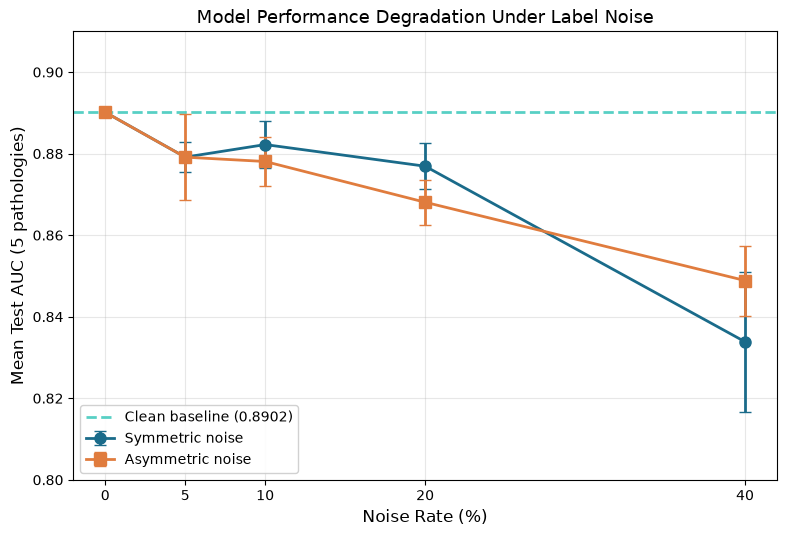

Saved: fig1_mean_auc_vs_noise.png/pdf


In [4]:
fig, ax = plt.subplots(1, 1, figsize=(8, 5.5))

COLOR_SYM = '#1A6B8A'
COLOR_ASYM = '#E07C3E'
COLOR_BASELINE = '#2EC4B6'

ax.axhline(BASELINE_MEAN_AUC, color=COLOR_BASELINE, linestyle='--', linewidth=2,
           label=f'Clean baseline ({BASELINE_MEAN_AUC:.4f})', alpha=0.8)

for nt, color, marker, label in [
    ('symmetric', COLOR_SYM, 'o', 'Symmetric noise'),
    ('asymmetric', COLOR_ASYM, 's', 'Asymmetric noise'),
]:
    sub = df[df['noise_type'] == nt].groupby('noise_rate')['test_mean_auc'].agg(['mean', 'std']).reset_index()
    baseline_row = pd.DataFrame({'noise_rate': [0.0], 'mean': [BASELINE_MEAN_AUC], 'std': [0.0]})
    sub = pd.concat([baseline_row, sub], ignore_index=True)
    
    ax.errorbar(sub['noise_rate']*100, sub['mean'], yerr=sub['std'],
                marker=marker, markersize=8, linewidth=2, capsize=4,
                color=color, label=label)

ax.set_xlabel('Noise Rate (%)')
ax.set_ylabel('Mean Test AUC (5 pathologies)')
ax.set_title('Model Performance Degradation Under Label Noise')
ax.set_xticks([0, 5, 10, 20, 40])
ax.grid(True, alpha=0.3)
ax.legend(loc='lower left', framealpha=0.9)
ax.set_ylim([0.80, 0.91])

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig1_mean_auc_vs_noise.png'), dpi=300)
plt.savefig(os.path.join(FIGURES_DIR, 'fig1_mean_auc_vs_noise.pdf'))
plt.show()
print(f"Saved: fig1_mean_auc_vs_noise.png/pdf")

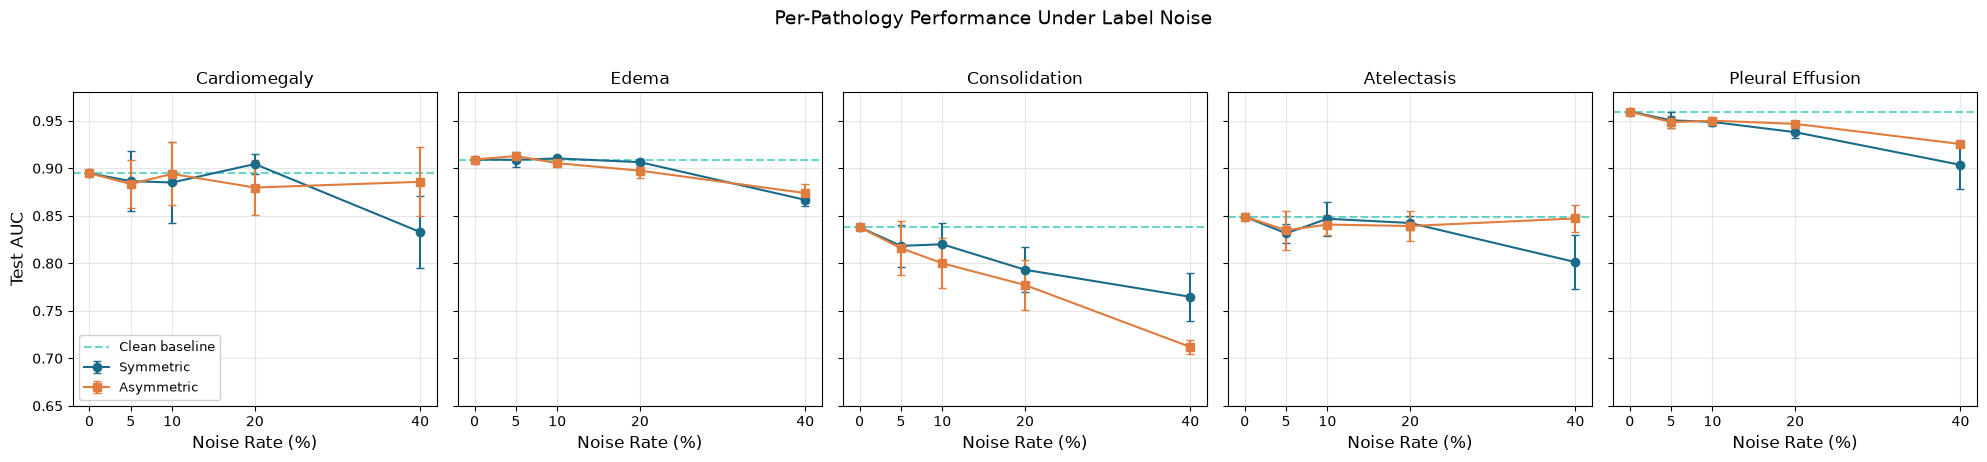

Saved: fig2_per_pathology.png/pdf


In [5]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5), sharey=True)

for ax, path in zip(axes, TARGET_PATHOLOGIES):
    col = f'test_{path.replace(" ", "_")}'
    baseline_val = BASELINE_PER_PATH[path]
    
    ax.axhline(baseline_val, color=COLOR_BASELINE, linestyle='--',
               linewidth=1.5, alpha=0.7, label='Clean baseline')
    
    for nt, color, marker in [('symmetric', COLOR_SYM, 'o'), 
                                ('asymmetric', COLOR_ASYM, 's')]:
        sub = df[df['noise_type']==nt].groupby('noise_rate')[col].agg(['mean', 'std']).reset_index()
        baseline_row = pd.DataFrame({'noise_rate': [0.0], 'mean': [baseline_val], 'std': [0.0]})
        sub = pd.concat([baseline_row, sub], ignore_index=True)
        
        ax.errorbar(sub['noise_rate']*100, sub['mean'], yerr=sub['std'],
                    marker=marker, markersize=6, linewidth=1.5, capsize=3,
                    color=color, label=nt.capitalize())
    
    ax.set_title(path, fontsize=12)
    ax.set_xlabel('Noise Rate (%)')
    ax.set_xticks([0, 5, 10, 20, 40])
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0.65, 0.98])

axes[0].set_ylabel('Test AUC')
axes[0].legend(loc='lower left', framealpha=0.9, fontsize=9)

plt.suptitle('Per-Pathology Performance Under Label Noise', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig2_per_pathology.png'), dpi=300)
plt.savefig(os.path.join(FIGURES_DIR, 'fig2_per_pathology.pdf'))
plt.show()
print(f"Saved: fig2_per_pathology.png/pdf")

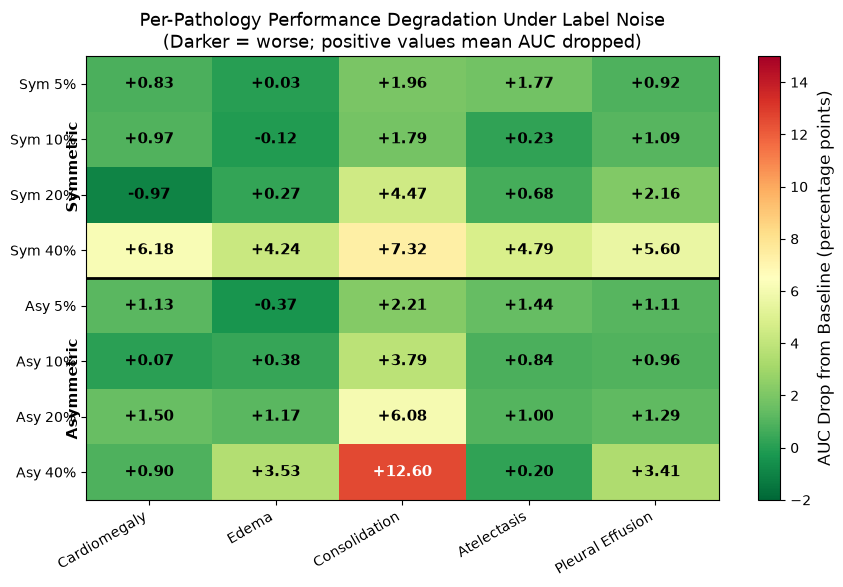

Saved: fig3_degradation_heatmap.png/pdf


In [6]:
conditions = []
condition_labels = []
for nt in ['symmetric', 'asymmetric']:
    for nr in [0.05, 0.10, 0.20, 0.40]:
        conditions.append((nt, nr))
        condition_labels.append(f"{nt.capitalize()[:3]} {int(nr*100)}%")

matrix = np.zeros((len(conditions), len(TARGET_PATHOLOGIES)))
for i, (nt, nr) in enumerate(conditions):
    sub = df[(df['noise_type']==nt) & (df['noise_rate']==nr)]
    for j, path in enumerate(TARGET_PATHOLOGIES):
        col = f'test_{path.replace(" ", "_")}'
        mean_auc = sub[col].mean()
        drop_pp = (BASELINE_PER_PATH[path] - mean_auc) * 100
        matrix[i, j] = drop_pp

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(matrix, cmap='RdYlGn_r', aspect='auto', vmin=-2, vmax=15)

for i in range(len(conditions)):
    for j in range(len(TARGET_PATHOLOGIES)):
        val = matrix[i, j]
        color = 'white' if abs(val) > 8 else 'black'
        ax.text(j, i, f'{val:+.2f}', ha='center', va='center',
                color=color, fontsize=11, fontweight='bold')

ax.set_xticks(range(len(TARGET_PATHOLOGIES)))
ax.set_xticklabels(TARGET_PATHOLOGIES, rotation=30, ha='right')
ax.set_yticks(range(len(conditions)))
ax.set_yticklabels(condition_labels)

ax.axhline(3.5, color='black', linewidth=2)  # separator between symmetric and asymmetric
ax.text(-0.6, 1.5, 'Symmetric', rotation=90, va='center', ha='center',
        fontweight='bold', fontsize=11)
ax.text(-0.6, 5.5, 'Asymmetric', rotation=90, va='center', ha='center',
        fontweight='bold', fontsize=11)

cbar = plt.colorbar(im, ax=ax, label='AUC Drop from Baseline (percentage points)')
ax.set_title('Per-Pathology Performance Degradation Under Label Noise\n(Darker = worse; positive values mean AUC dropped)')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig3_degradation_heatmap.png'), dpi=300)
plt.savefig(os.path.join(FIGURES_DIR, 'fig3_degradation_heatmap.pdf'))
plt.show()
print(f"Saved: fig3_degradation_heatmap.png/pdf")

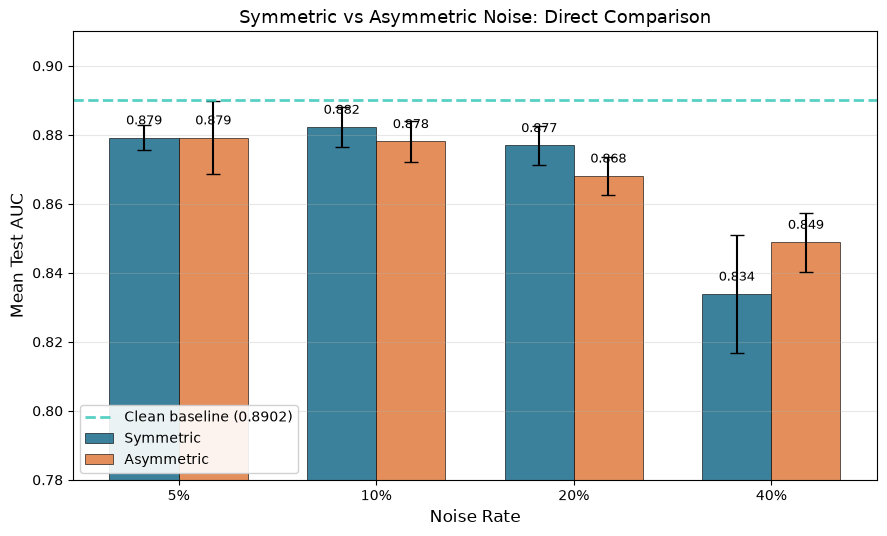

Saved: fig4_sym_vs_asym.png/pdf


In [7]:
fig, ax = plt.subplots(figsize=(9, 5.5))

noise_rates = [0.05, 0.10, 0.20, 0.40]
x = np.arange(len(noise_rates))
width = 0.35

sym_means = [df[(df['noise_type']=='symmetric') & (df['noise_rate']==r)]['test_mean_auc'].mean() for r in noise_rates]
sym_stds = [df[(df['noise_type']=='symmetric') & (df['noise_rate']==r)]['test_mean_auc'].std() for r in noise_rates]
asym_means = [df[(df['noise_type']=='asymmetric') & (df['noise_rate']==r)]['test_mean_auc'].mean() for r in noise_rates]
asym_stds = [df[(df['noise_type']=='asymmetric') & (df['noise_rate']==r)]['test_mean_auc'].std() for r in noise_rates]

bars1 = ax.bar(x - width/2, sym_means, width, yerr=sym_stds, capsize=5,
                color=COLOR_SYM, label='Symmetric', alpha=0.85, edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, asym_means, width, yerr=asym_stds, capsize=5,
                color=COLOR_ASYM, label='Asymmetric', alpha=0.85, edgecolor='black', linewidth=0.5)

ax.axhline(BASELINE_MEAN_AUC, color=COLOR_BASELINE, linestyle='--',
           linewidth=2, alpha=0.8, label=f'Clean baseline ({BASELINE_MEAN_AUC:.4f})')

for bars, means in [(bars1, sym_means), (bars2, asym_means)]:
    for bar, val in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.003, f'{val:.3f}',
                ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Noise Rate')
ax.set_ylabel('Mean Test AUC')
ax.set_title('Symmetric vs Asymmetric Noise: Direct Comparison')
ax.set_xticks(x)
ax.set_xticklabels([f'{int(r*100)}%' for r in noise_rates])
ax.legend(loc='lower left', framealpha=0.9)
ax.set_ylim([0.78, 0.91])
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig4_sym_vs_asym.png'), dpi=300)
plt.savefig(os.path.join(FIGURES_DIR, 'fig4_sym_vs_asym.pdf'))
plt.show()
print(f"Saved: fig4_sym_vs_asym.png/pdf")

In [8]:
print("=== One-sample t-test: Noise condition vs baseline AUC ===")
print(f"H0: mean AUC = {BASELINE_MEAN_AUC:.4f} (baseline)")
print(f"H1: mean AUC != baseline\n")
print(f"{'Condition':<25} {'Mean':<10} {'t-stat':<10} {'p-value':<12} {'Significant?':<15}")
print("-" * 75)

for nt in ['symmetric', 'asymmetric']:
    for nr in [0.05, 0.10, 0.20, 0.40]:
        sub = df[(df['noise_type']==nt) & (df['noise_rate']==nr)]['test_mean_auc'].values
        t_stat, p_val = stats.ttest_1samp(sub, BASELINE_MEAN_AUC)
        sig = "YES (p<0.05)" if p_val < 0.05 else "NO"
        cond = f"{nt.capitalize()} {int(nr*100)}%"
        print(f"{cond:<25} {sub.mean():<10.4f} {t_stat:<10.3f} {p_val:<12.4f} {sig:<15}")

=== One-sample t-test: Noise condition vs baseline AUC ===
H0: mean AUC = 0.8902 (baseline)
H1: mean AUC != baseline

Condition                 Mean       t-stat     p-value      Significant?   
---------------------------------------------------------------------------
Symmetric 5%              0.8791     -5.260     0.0343       YES (p<0.05)   
Symmetric 10%             0.8822     -2.401     0.1384       NO             
Symmetric 20%             0.8769     -4.046     0.0560       NO             
Symmetric 40%             0.8339     -5.666     0.0298       YES (p<0.05)   
Asymmetric 5%             0.8791     -1.803     0.2131       NO             
Asymmetric 10%            0.8781     -3.447     0.0748       NO             
Asymmetric 20%            0.8681     -6.957     0.0200       YES (p<0.05)   
Asymmetric 40%            0.8489     -8.330     0.0141       YES (p<0.05)   


In [9]:
print("=== Two-sample t-test: Symmetric vs Asymmetric at same noise rate ===\n")
print(f"{'Rate':<10} {'Sym mean':<12} {'Asym mean':<12} {'Difference':<12} {'t-stat':<10} {'p-value':<12} {'Significant?':<15}")
print("-" * 90)

for nr in [0.05, 0.10, 0.20, 0.40]:
    sym = df[(df['noise_type']=='symmetric') & (df['noise_rate']==nr)]['test_mean_auc'].values
    asym = df[(df['noise_type']=='asymmetric') & (df['noise_rate']==nr)]['test_mean_auc'].values
    t_stat, p_val = stats.ttest_ind(sym, asym)
    sig = "YES (p<0.05)" if p_val < 0.05 else "NO"
    diff = sym.mean() - asym.mean()
    print(f"{int(nr*100):<3d}%     {sym.mean():<12.4f} {asym.mean():<12.4f} {diff:+.4f}      {t_stat:<10.3f} {p_val:<12.4f} {sig:<15}")

=== Two-sample t-test: Symmetric vs Asymmetric at same noise rate ===

Rate       Sym mean     Asym mean    Difference   t-stat     p-value      Significant?   
------------------------------------------------------------------------------------------
5  %     0.8791       0.8791       +0.0000      0.001      0.9992       NO             
10 %     0.8822       0.8781       +0.0041      0.862      0.4372       NO             
20 %     0.8769       0.8681       +0.0088      1.940      0.1243       NO             
40 %     0.8339       0.8489       -0.0150      -1.353     0.2475       NO             


In [10]:
def format_mean_std(m, s):
    if s == 0:
        return f"{m:.4f}"
    return f"{m:.4f} $\\pm$ {s:.4f}"

latex_lines = [
    "\\begin{table}[h]",
    "\\centering",
    "\\caption{Test set AUC under symmetric and asymmetric label noise. " 
        "Mean $\\pm$ standard deviation across 3 random seeds. "
        "Baseline shown for reference.}",
    "\\label{tab:noise_results}",
    "\\begin{tabular}{llcccccc}",
    "\\toprule",
    "Condition & Rate & Mean AUC & Cardio. & Edema & Consol. & Atel. & P. Effusion \\\\",
    "\\midrule",
]

row = f"Clean & -- & {BASELINE_MEAN_AUC:.4f} "
for p in TARGET_PATHOLOGIES:
    row += f"& {BASELINE_PER_PATH[p]:.4f} "
row += "\\\\"
latex_lines.append(row)
latex_lines.append("\\midrule")

for nr in [0.05, 0.10, 0.20, 0.40]:
    sub = df[(df['noise_type']=='symmetric') & (df['noise_rate']==nr)]
    row = f"Symmetric & {int(nr*100)}\\% & {format_mean_std(sub['test_mean_auc'].mean(), sub['test_mean_auc'].std())} "
    for p in TARGET_PATHOLOGIES:
        col = f'test_{p.replace(" ", "_")}'
        row += f"& {format_mean_std(sub[col].mean(), sub[col].std())} "
    row += "\\\\"
    latex_lines.append(row)

latex_lines.append("\\midrule")

for nr in [0.05, 0.10, 0.20, 0.40]:
    sub = df[(df['noise_type']=='asymmetric') & (df['noise_rate']==nr)]
    row = f"Asymmetric & {int(nr*100)}\\% & {format_mean_std(sub['test_mean_auc'].mean(), sub['test_mean_auc'].std())} "
    for p in TARGET_PATHOLOGIES:
        col = f'test_{p.replace(" ", "_")}'
        row += f"& {format_mean_std(sub[col].mean(), sub[col].std())} "
    row += "\\\\"
    latex_lines.append(row)

latex_lines.extend([
    "\\bottomrule",
    "\\end{tabular}",
    "\\end{table}",
])

latex_str = '\n'.join(latex_lines)

latex_path = os.path.join(RESULTS_DIR, 'noise_results_table.tex')
with open(latex_path, 'w') as f:
    f.write(latex_str)

print(f"LaTeX table saved to: {latex_path}\n")
print(latex_str)

LaTeX table saved to: ..\results\noise_experiments\noise_results_table.tex

\begin{table}[h]
\centering
\caption{Test set AUC under symmetric and asymmetric label noise. Mean $\pm$ standard deviation across 3 random seeds. Baseline shown for reference.}
\label{tab:noise_results}
\begin{tabular}{llcccccc}
\toprule
Condition & Rate & Mean AUC & Cardio. & Edema & Consol. & Atel. & P. Effusion \\
\midrule
Clean & -- & 0.8902 & 0.8947 & 0.9092 & 0.8380 & 0.8492 & 0.9597 \\
\midrule
Symmetric & 5\% & 0.8791 $\pm$ 0.0036 & 0.8865 $\pm$ 0.0316 & 0.9089 $\pm$ 0.0078 & 0.8184 $\pm$ 0.0222 & 0.8315 $\pm$ 0.0096 & 0.9505 $\pm$ 0.0082 \\
Symmetric & 10\% & 0.8822 $\pm$ 0.0057 & 0.8851 $\pm$ 0.0424 & 0.9104 $\pm$ 0.0026 & 0.8200 $\pm$ 0.0225 & 0.8469 $\pm$ 0.0181 & 0.9488 $\pm$ 0.0045 \\
Symmetric & 20\% & 0.8769 $\pm$ 0.0057 & 0.9045 $\pm$ 0.0102 & 0.9065 $\pm$ 0.0028 & 0.7932 $\pm$ 0.0236 & 0.8424 $\pm$ 0.0070 & 0.9380 $\pm$ 0.0065 \\
Symmetric & 40\% & 0.8339 $\pm$ 0.0172 & 0.8329 $\pm$ 0.0380 & 

In [11]:
print("=" * 70)
print("KEY FINDINGS SUMMARY")
print("=" * 70)

print(f"\n1. CLEAN BASELINE performance: {BASELINE_MEAN_AUC:.4f} mean test AUC")

worst_row = None
worst_auc = 1.0
for _, row in agg_df.iterrows():
    if row['noise_type'] != 'clean' and row['mean_auc'] < worst_auc:
        worst_auc = row['mean_auc']
        worst_row = row

worst_cond = f"{worst_row['noise_type'].capitalize()} {int(worst_row['noise_rate']*100)}%"
print(f"\n2. WORST-CASE noise condition: {worst_cond}")
print(f"   Mean AUC: {worst_row['mean_auc']:.4f} ± {worst_row['std_auc']:.4f}")
print(f"   Degradation: {(BASELINE_MEAN_AUC - worst_row['mean_auc'])*100:.2f} percentage points")

sym_10 = df[(df['noise_type']=='symmetric') & (df['noise_rate']==0.10)]['test_mean_auc'].mean()
print(f"\n3. ROBUSTNESS at realistic noise levels (10% symmetric): {sym_10:.4f}")
print(f"   Only {(BASELINE_MEAN_AUC - sym_10)*100:.2f}pp below baseline")
print(f"   -> DenseNet-121 is robust to 5-10% label noise (realistic levels)")

sym_20 = df[(df['noise_type']=='symmetric') & (df['noise_rate']==0.20)]['test_mean_auc'].mean()
asym_20 = df[(df['noise_type']=='asymmetric') & (df['noise_rate']==0.20)]['test_mean_auc'].mean()
print(f"\n4. SYMMETRIC vs ASYMMETRIC at 20% noise:")
print(f"   Symmetric:  {sym_20:.4f}")
print(f"   Asymmetric: {asym_20:.4f}")
print(f"   Difference: {(sym_20-asym_20)*100:+.2f}pp")
if asym_20 < sym_20:
    print(f"   -> Asymmetric (clinically plausible) noise is MORE harmful than random noise")

print(f"\n5. MOST NOISE-SENSITIVE pathology:")
max_drop = 0
worst_path = None
worst_cond_path = None
for nt in ['symmetric', 'asymmetric']:
    for nr in [0.05, 0.10, 0.20, 0.40]:
        sub = df[(df['noise_type']==nt) & (df['noise_rate']==nr)]
        for path in TARGET_PATHOLOGIES:
            col = f'test_{path.replace(" ", "_")}'
            drop = (BASELINE_PER_PATH[path] - sub[col].mean()) * 100
            if drop > max_drop:
                max_drop = drop
                worst_path = path
                worst_cond_path = f"{nt} {int(nr*100)}%"

print(f"   {worst_path} under {worst_cond_path}")
print(f"   Baseline: {BASELINE_PER_PATH[worst_path]:.4f}")
print(f"   Under noise: {BASELINE_PER_PATH[worst_path] - max_drop/100:.4f}")
print(f"   Drop: {max_drop:.2f} percentage points")

avg_std = df.groupby(['noise_type', 'noise_rate'])['test_mean_auc'].std().mean()
print(f"\n6. REPRODUCIBILITY:")
print(f"   Average std across seeds: {avg_std:.4f}")
print(f"   -> Results are highly reproducible (low variance across seeds)")

print("\n" + "=" * 70)
print("Analysis complete.")
print(f"All figures saved to: {FIGURES_DIR}")
print(f"Aggregated table: {os.path.join(RESULTS_DIR, 'aggregated_summary.csv')}")
print(f"LaTeX table: {os.path.join(RESULTS_DIR, 'noise_results_table.tex')}")
print("=" * 70)

KEY FINDINGS SUMMARY

1. CLEAN BASELINE performance: 0.8902 mean test AUC

2. WORST-CASE noise condition: Symmetric 40%
   Mean AUC: 0.8339 ± 0.0172
   Degradation: 5.63 percentage points

3. ROBUSTNESS at realistic noise levels (10% symmetric): 0.8822
   Only 0.79pp below baseline
   -> DenseNet-121 is robust to 5-10% label noise (realistic levels)

4. SYMMETRIC vs ASYMMETRIC at 20% noise:
   Symmetric:  0.8769
   Asymmetric: 0.8681
   Difference: +0.88pp
   -> Asymmetric (clinically plausible) noise is MORE harmful than random noise

5. MOST NOISE-SENSITIVE pathology:
   Consolidation under asymmetric 40%
   Baseline: 0.8380
   Under noise: 0.7120
   Drop: 12.60 percentage points

6. REPRODUCIBILITY:
   Average std across seeds: 0.0079
   -> Results are highly reproducible (low variance across seeds)

Analysis complete.
All figures saved to: ..\results\figures
Aggregated table: ..\results\noise_experiments\aggregated_summary.csv
LaTeX table: ..\results\noise_experiments\noise_results